In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

CANDIDATES = [Path(os.environ["SMART_BUILDINGS_DATA_ROOT"])] if os.getenv("SMART_BUILDINGS_DATA_ROOT") else []
CANDIDATES += [
    Path("/kaggle/input/competitions/neurips-2026-smart-buildings"),
    Path("/kaggle/input/neurips-2026-smart-buildings"),
]
DATA_ROOT = next((p for p in CANDIDATES if (p / "smart_buildings").is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError(
        "Competition data not found. Attach it to the notebook or set SMART_BUILDINGS_DATA_ROOT. Checked: %s" % CANDIDATES
    )
for sub in (DATA_ROOT, DATA_ROOT / "kaggle_evaluation"):
    if not sub.is_dir():
        raise FileNotFoundError("Missing folder: %s" % sub)
    sys.path.insert(0, str(sub))

IS_RERUN = os.getenv("KAGGLE_IS_COMPETITION_RERUN") is not None
print("Data root:", DATA_ROOT, "| hidden rerun:", IS_RERUN)

Data root: /kaggle/input/competitions/neurips-2026-smart-buildings | hidden rerun: False


## Exploratory data analysis

Training set: 6 buildings x 5 climates = 30 scenarios (30-85 zones, 3-9 AHUs per building).
The cell below reports building size, observation and action dimensions, initial NaNs, material
properties, a floor-plan grid, and the 30-day outside-temperature range per climate.
Key facts for control design: a zero continuous action is mid-range (half-open damper), not off;
AHUs can only cool; heating comes from zone hot-water reheat, which needs airflow.

In [2]:
"""EDA of released training data; never opens evaluation_scenarios."""
import os
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml


def analyze_data(data_root, output_root):
    data_root = Path(data_root).resolve()
    output_root = Path(output_root).resolve()
    output_root.mkdir(parents=True, exist_ok=True)
    from smart_buildings.evaluate import load_hybrid_environment, create_building_meta_data
    previous = Path.cwd()
    buildings, weather_rows = [], []
    frames = {}
    try:
        os.chdir(data_root)
        scenario_dirs = sorted((data_root / "smart_buildings/training_scenarios").glob("*/*"))
        seen = set()
        for scenario in scenario_dirs:
            if not (scenario / "config.gin").exists():
                continue
            cfg = yaml.safe_load((scenario / "config.yaml").read_text())
            if scenario.parent.name not in seen:
                seen.add(scenario.parent.name)
                env = load_hybrid_environment(scenario / "config.gin")
                # Competition input is read-only on Kaggle, including metric paths.
                env.metrics_path = None
                meta = create_building_meta_data(env, scenario)
                obs, _ = env.reset()
                assert np.isfinite(obs).all(), "Non-finite initial observation"
                names = meta["observation_field_names"]
                zone_fields = [n for n in names if n.endswith("_zone_air_temperature_sensor")]
                v, k = len(meta["zone_action_indices"]), len(meta["temp_indices"])
                assert meta["n_continuous_action"] == 3*k + 2 + 2*v
                assert len(zone_fields) == v
                floor = np.load(scenario / "floor_plan.npy")
                buildings.append(dict(
                    building=scenario.parent.name, floors=meta["num_floors"],
                    zones=v, ahus=k, observation_dim=len(names),
                    continuous_dim=meta["n_continuous_action"],
                    discrete_dim=meta["n_discrete_action"],
                    grid_cells=int(floor.size), initial_missing=int(np.isnan(obs).sum()),
                    exterior_conductivity=cfg["materials"]["exterior_cv_conductivity"],
                    exterior_density=cfg["materials"]["exterior_cv_density"],
                    interior_mass_density=cfg["materials"]["interior_mass_cv_density"],
                ))
                if len(buildings) == 1:
                    pd.DataFrame(dict(field=names, initial_observation=obs)).to_csv(
                        output_root / "observation_example.csv", index=False)
                    for key in ("observation_normalization_metadata", "action_normalization_metadata"):
                        import json
                        (output_root / f"{key}.json").write_text(json.dumps(meta[key], indent=2))
                    fig, ax = plt.subplots(figsize=(9, 5))
                    ax.imshow(floor, cmap="viridis", interpolation="nearest")
                    ax.set(title=f"{scenario.parent.name}: simulator floor grid", xlabel="grid column", ylabel="grid row")
                    fig.tight_layout(); fig.savefig(output_root / "floor_plan.png", dpi=150); plt.close(fig)
            csv = data_root / "smart_buildings/weather" / cfg["weather"]["weather_csv"]
            if csv not in frames:
                frame = pd.read_csv(csv)
                frame["timestamp"] = pd.to_datetime(frame["Time"], utc=True)
                frames[csv] = frame
            frame = frames[csv]
            # Gin's actual simulator clock takes the weather override.
            start = pd.Timestamp(cfg["weather"]["start_timestamp"], tz="UTC")
            days = int(cfg["simulation"]["num_days_in_episode"])
            window = frame[(frame.timestamp >= start) & (frame.timestamp < start + pd.Timedelta(days=days))]
            temp = (window.TempF - 32) * (5/9)
            weather_rows.append(dict(
                building=scenario.parent.name, weather=scenario.name,
                station=scenario.name.rsplit("_", 1)[0], start=str(start),
                hours=len(window), missing_temperatures=int(temp.isna().sum()),
                duplicate_timestamps=int(window.timestamp.duplicated().sum()),
                min_C=float(temp.min()), mean_C=float(temp.mean()), max_C=float(temp.max()),
                hours_below_minus6_8_pct=float(100*(temp < -6.8).mean()),
            ))
    finally:
        os.chdir(previous)
    building_df, weather_df = pd.DataFrame(buildings), pd.DataFrame(weather_rows)
    building_df.to_csv(output_root / "buildings.csv", index=False)
    weather_df.to_csv(output_root / "weather_strips.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    building_df.plot.bar(x="building", y=["zones", "ahus"], ax=axes[0], rot=25)
    axes[0].set_title("Variable building and action size")
    grouped = weather_df.groupby("station").agg(min_C=("min_C", "min"), mean_C=("mean_C", "mean"), max_C=("max_C", "max"))
    x = np.arange(len(grouped))
    axes[1].vlines(x, grouped.min_C, grouped.max_C, linewidth=5, color="#3b82f6")
    axes[1].scatter(x, grouped.mean_C, color="#f97316", label="mean across strips")
    axes[1].set(xticks=x, xticklabels=grouped.index, ylabel="outside temperature (C)", title="30-day training weather windows")
    axes[1].legend(); fig.tight_layout(); fig.savefig(output_root / "eda.png", dpi=150); plt.close(fig)
    print(building_df.to_string(index=False))
    print(grouped.round(2).to_string())
    print(f"Scenarios: {len(weather_df)}, initial observation NaNs: {building_df.initial_missing.sum()}")
    return building_df, weather_df


        building  floors  zones  ahus  observation_dim  continuous_dim  discrete_dim  grid_cells  initial_missing  exterior_conductivity  exterior_density  interior_mass_density
building_train_1       3     39     4              352              92             5      205434                0                 0.2119         1967.2446                32.2919
building_train_2       2     85     9              703             199            10      263328                0                 0.3385          577.6431                14.3595
building_train_4       3     54     6              472             128             7      286848                0                 0.1820          474.8436                23.3826
building_train_5       4     79     8              652             184             9      293436                0                 0.3041         1187.2131                28.0107
building_train_7       2     36     4              334              86             5      127782              

,building,floors,zones,ahus,observation_dim,continuous_dim,discrete_dim,grid_cells,initial_missing,exterior_conductivity,exterior_density,interior_mass_density
0,building_train_1,3,39,4,352,92,5,205434,0,0.2119,1967.2446,32.2919
1,building_train_2,2,85,9,703,199,10,263328,0,0.3385,577.6431,14.3595
2,building_train_4,3,54,6,472,128,7,286848,0,0.1820,474.8436,23.3826
3,building_train_5,4,79,8,652,184,9,293436,0,0.3041,1187.2131,28.0107
4,building_train_7,2,36,4,334,86,5,127782,0,0.5479,414.8160,35.6803
5,building_train_8,2,30,3,283,71,4,123520,0,0.2703,1138.8883,11.4679


,building,weather,station,start,hours,missing_temperatures,duplicate_timestamps,min_C,mean_C,max_C,hours_below_minus6_8_pct
0,building_train_1,atlanta_2,atlanta,2023-03-05 06:00:00+00:00,720,0,0,-3.9,14.508611,29.4,0.000000
1,building_train_1,denver_7,denver,2023-09-24 06:00:00+00:00,720,0,0,0.2,12.935833,28.3,0.000000
2,building_train_1,fairbanks_1,fairbanks,2023-01-01 06:00:00+00:00,720,0,0,-42.0,-21.407500,1.1,88.194444
3,building_train_1,phoenix_5,phoenix,2023-07-16 06:00:00+00:00,720,0,0,25.0,36.824306,46.1,0.000000
4,building_train_1,singapore_8,singapore,2023-11-26 06:00:00+00:00,720,0,0,23.0,26.898889,33.1,0.000000
5,building_train_2,atlanta_3,atlanta,2023-04-16 06:00:00+00:00,720,0,0,8.0,20.814583,30.6,0.000000
6,building_train_2,denver_8,denver,2023-11-05 06:00:00+00:00,720,0,0,-12.8,6.085972,26.7,1.944444
7,building_train_2,fairbanks_2,fairbanks,2023-02-12 06:00:00+00:00,720,0,0,-25.6,-8.184722,4.4,55.416667
8,building_train_2,phoenix_6,phoenix,2023-08-27 06:00:00+00:00,720,0,0,23.9,33.149583,42.8,0.000000
9,building_train_2,singapore_1,singapore,2023-02-05 06:00:00+00:00,720,0,0,23.5,27.328194,33.0,0.000000


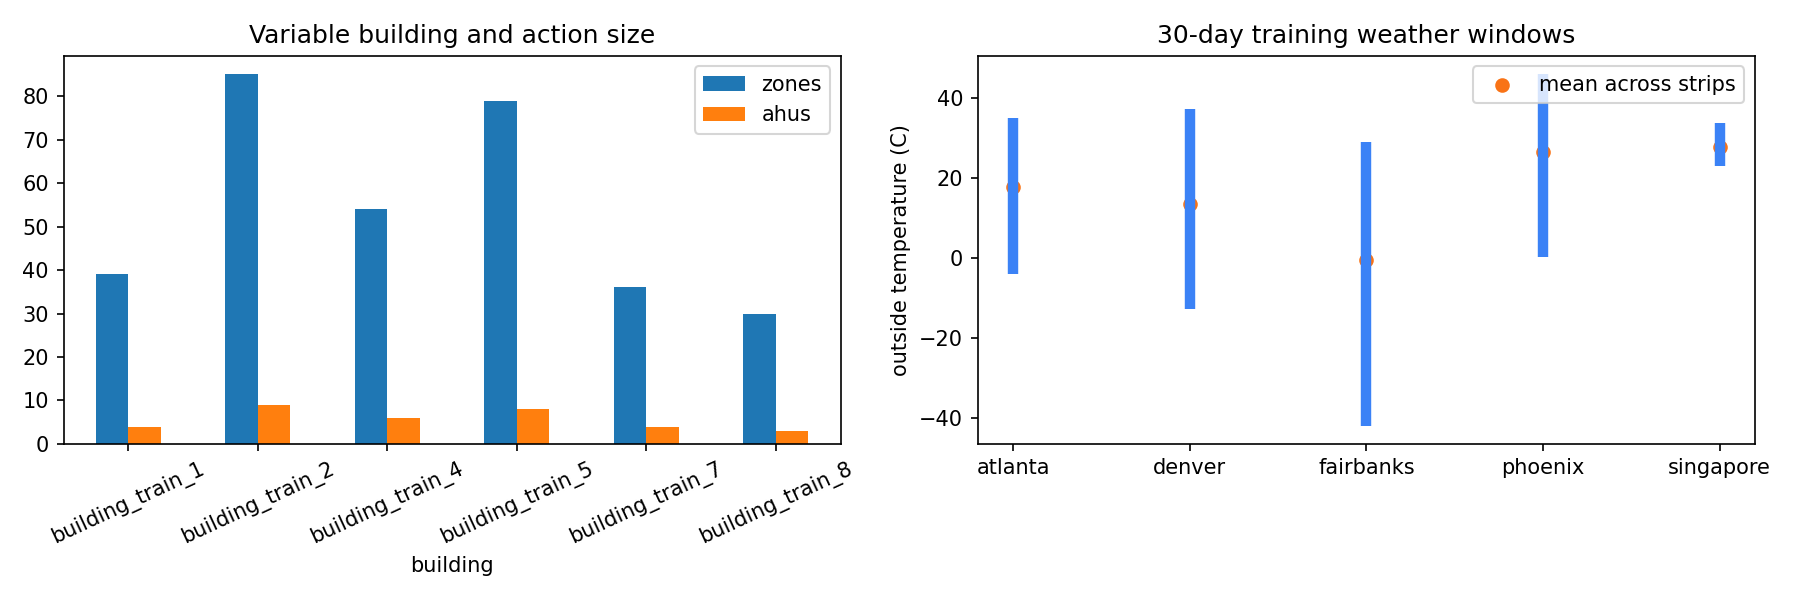

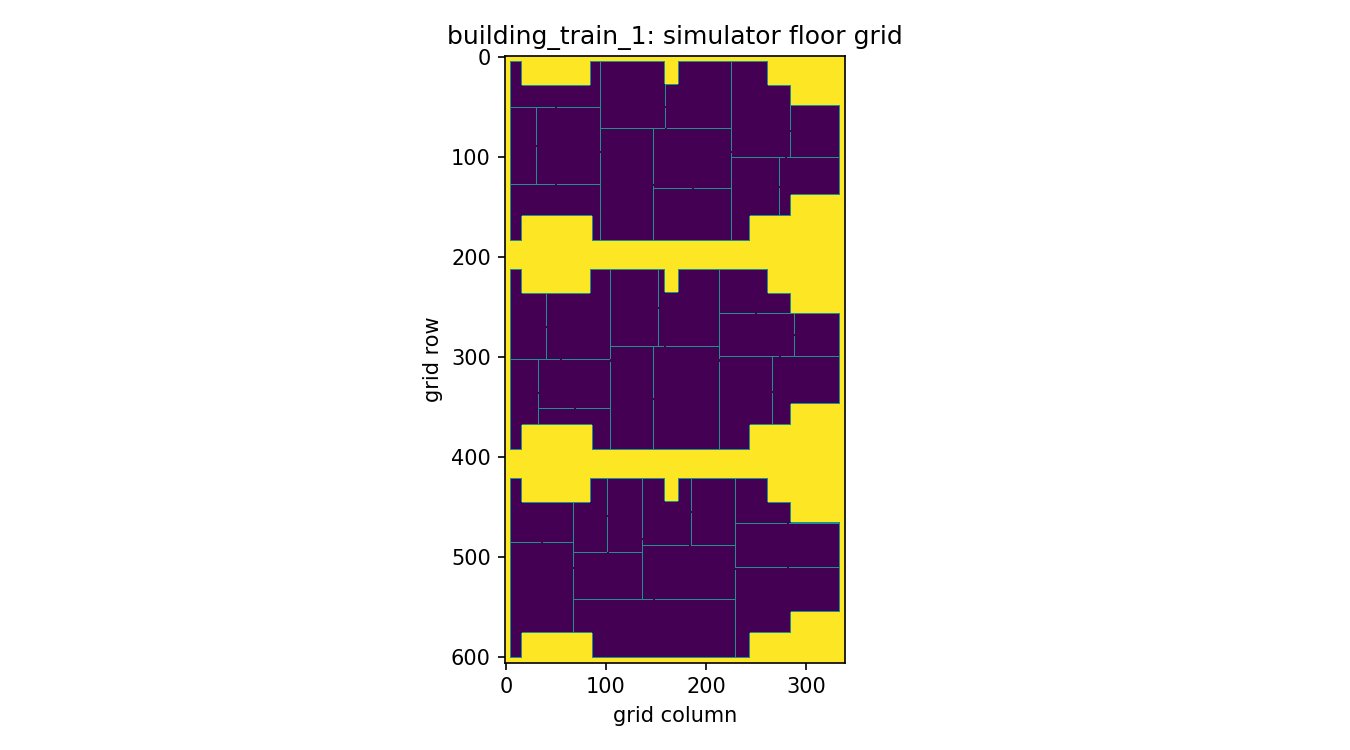

In [3]:
# EDA reads published training scenarios only and is skipped in the hidden rerun.
# Failure here must never block the submission, so it is wrapped.
if not IS_RERUN:
    try:
        buildings, weather = analyze_data(DATA_ROOT, Path("/kaggle/working/eda") if Path("/kaggle/working").exists() else Path("eda"))
        from IPython.display import display, Image
        display(buildings)
        display(weather)
        display(Image(filename=str(Path("/kaggle/working/eda/eda.png"))))
        display(Image(filename=str(Path("/kaggle/working/eda/floor_plan.png"))))
    except Exception as exc:
        print("EDA skipped:", repr(exc))

## Controllers

Actuator indices come from each building's metadata, so the policy adapts to any number of zones and AHUs.

In [ ]:
import numpy as np
from smart_buildings.baselines.pid_plus import PIDWaterResetPolicy

"""Full controller chain (port of the LB-verified ZonePI skeleton) + Stage-2/3
economics: minimum pressure on running AHUs, demand-shifted zone targets,
occupant-gated PI hours, and per-AHU SAT depth from load mixedness.
Builds on the Apache-2.0 organizer PIDWaterResetPolicy."""


def _outside_kelvin(policy, value):
    """AHU outside-air sensors arrive in raw kelvin; decode only if normalized."""
    value = float(value)
    return value if value > 150.0 else value * policy.outside_std + policy.outside_mean



class BaselinePolicy(PIDWaterResetPolicy):
    """First baseline: sensor comfort bands, mean zone, decoded weather.

    The version submitted as ``transfer`` on the public leaderboard (0.06439).
    """

    USE_SENSOR_BAND = True
    # Worst-zone aggregation increased loss in both full-length pilot scenarios.
    USE_WORST_ZONE = False

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        stats = self.observation_normalization_metadata.get(
            "outside_air_temperature_sensor", {}
        )
        self.outside_mean = float(stats.get("sample_mean", 0.0))
        self.outside_std = float(stats.get("sample_std", 1.0))

    def _recirculation(self, obs, ctrl, u, low, high):
        # The parent's economizer expects kelvin; the observation is standardized.
        idx = ctrl.get("oat_idx")
        if idx is None:
            return 1.0
        decoded = obs.copy()
        decoded[idx] = obs[idx] * self.outside_std + self.outside_mean
        return super()._recirculation(decoded, ctrl, u, low, high)

    def get_action(self, obs):
        action = super().get_action(obs)
        # Enforce the gateway's dtype, shape and bounds contract.
        for key, dtype in (("continuous_action", np.float32),
                           ("discrete_action", np.int32)):
            space = self.action_spec[key]
            action[key] = np.clip(action[key], space.low, space.high).astype(dtype)
        return action


class CoolingHoldPolicy(BaselinePolicy):
    """Baseline plus a cooling-run hold (and the optional night ceiling)."""

    HOLD_STEPS = 288
    # Outside work hours use (eco low, comfort high): no overnight drift up to
    # the eco ceiling in hot climates, full heating setback kept in cold ones.
    NIGHT_COOL_CEILING = True

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        self._on_steps = [0] * len(self.ahu_controllers)
        self._last_on = [None] * len(self.ahu_controllers)

    def _base_action(self, obs):
        if not self.NIGHT_COOL_CEILING:
            return super().get_action(obs)
        hour, day = self._get_hour_and_day(obs)
        if day < 5 and self.morning_start_hour <= hour < self.evening_start_hour:
            return super().get_action(obs)
        saved = self.eco_temp_window
        self.eco_temp_window = (saved[0], self.comfort_temp_window[1])
        try:
            return super().get_action(obs)
        finally:
            self.eco_temp_window = saved

    def get_action(self, obs):
        action = self._base_action(obs)
        cont, disc = action["continuous_action"], action["discrete_action"]
        for i, ctrl in enumerate(self.ahu_controllers):
            if not ctrl["zone_obs_indices"]:
                continue
            run = ctrl["run_discrete_idx"]
            # Supply temperature first: its sign tells cooling from heating.
            idx = [j for j in (ctrl["temp_idx"], ctrl["pressure_idx"], ctrl.get("recirc_idx"))
                   if j is not None]
            if (not disc[run] and self._on_steps[i] > 0
                    and self._on_steps[i] < self.HOLD_STEPS and self._last_on[i][0] < 0):
                disc[run] = 1
                cont[idx] = self._last_on[i]
            if disc[run]:
                self._on_steps[i] += 1
                self._last_on[i] = cont[idx].copy()
            else:
                self._on_steps[i] = 0
        return action


class ZonePIPolicy(CoolingHoldPolicy):
    """Per-zone PI control to the band centre in work hours.

    One signal u in [-1, 1] drives both actuators: the damper opens with |u|
    (air is needed to cool and to carry reheat) and the reheat valve opens
    with -u. AHUs are kept running in those hours so the zones have air to
    work with. Outside them, the cooling-hold logic is unchanged.

    Class defaults below match the k10 leaderboard probe (public LB 0.01853).
    """

    HOLD_STEPS = 288
    NIGHT_COOL_CEILING = True
    KP = 0.1
    KI = 0.005
    PRESTART_H = 1
    FORCED_SAT = -0.7       # normalized supply temp for a forced-on AHU (~15 C)
    FORCED_PRESSURE = -1.0  # normalized static pressure for a forced-on AHU
    MIN_DAMPER = 0.1
    # Damper opening per unit of heating demand (reheated air costs gas).
    HEAT_DAMPER_GAIN = 1.0
    KEY = "zone_pi"

    @property
    def name(self):
        return self.KEY

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        self._zone_integral = {}
        self._zone_u = {}
        self._pi_active = False

    def _pi_hours(self, obs):
        hour, day = self._get_hour_and_day(obs)
        return (day < 5
                and self.morning_start_hour - self.PRESTART_H <= hour
                < self.evening_start_hour)

    def _command_zones(self, continuous, zones, obs, low, high):
        if not self._pi_active:
            for vav_id, _, _ in zones:
                self._zone_integral[vav_id] = 0.0
            return super()._command_zones(continuous, zones, obs, low, high)
        lo_c, hi_c = self.comfort_temp_window
        for vav_id, obs_idx, action_indices in zones:
            if not action_indices:
                continue
            lo, hi = self._zone_band(obs, vav_id, lo_c, hi_c)
            # Before occupancy the sensor band is still the eco band; aim
            # at comfort.
            if hi - lo > (hi_c - lo_c) + 1e-6:
                lo, hi = lo_c, hi_c
            err = self._zone_err(
                obs, self._denormalize_zone_temp(obs[obs_idx]), lo, hi
            )
            integral = self._zone_integral.get(vav_id, 0.0)
            integral = self._zone_integral_update(err, integral)
            self._zone_integral[vav_id] = integral
            u = float(np.clip(self.KP * err + self.KI * integral, -1.0, 1.0))
            self._max_heat = max(self._max_heat, -u)
            self._zone_u[vav_id] = u
            damper, reheat = self._zone_output_map(u)
            damper_idx = action_indices.get("supply_air_damper_percentage_command")
            if damper_idx is not None:
                continuous[damper_idx] = 2.0 * damper - 1.0
            reheat_idx = action_indices.get("reheat_valve_percentage_command")
            if reheat_idx is not None:
                continuous[reheat_idx] = 2.0 * reheat - 1.0

    def _zone_target(self, obs, lo, hi):
        """Temperature each zone's PI loop aims at; the band centre by default."""
        return 0.5 * (lo, hi)[0] + 0.5 * (lo, hi)[1]

    def _zone_output_map(self, u):
        """(damper_01, reheat_01) from PI signal u in [-1, 1].

        Coupled by default: the damper opens with |u| and the reheat valve
        with -u simultaneously. Override for decoupled (dual-maximum) maps.
        """
        gain = self.HEAT_DAMPER_GAIN if u < 0 else 1.0
        damper = self.MIN_DAMPER + (1.0 - self.MIN_DAMPER) * abs(u) * gain
        reheat = max(0.0, -u)
        return damper, reheat

    def _zone_err(self, obs, temp, lo, hi):
        """PI error for a zone at temperature temp with band [lo, hi].

        Default: deviation from the (possibly shifted) band target.
        Override for deadband edge-riding.
        """
        return temp - self._zone_target(obs, lo, hi)

    def _zone_integral_update(self, err, integral):
        """Conditional integration: stop winding up while saturated."""
        u_raw = self.KP * err + self.KI * integral
        if abs(u_raw) < 1.0 or np.sign(err) != np.sign(u_raw):
            integral = float(np.clip(integral + err, -1.0 / self.KI,
                                     1.0 / self.KI))
        return integral

    def _base_action(self, obs):
        self._pi_active = self._pi_hours(obs)
        self._max_heat = 0.0
        self._forced = []
        self._zone_u = {}
        action = super()._base_action(obs)
        if self._pi_active:
            cont, disc = action["continuous_action"], action["discrete_action"]
            # Zone reheat needs hot water even when no AHU loop asks for heat.
            if self.water_temp_idx is not None and self._max_heat > 0:
                cont[self.water_temp_idx] = max(cont[self.water_temp_idx],
                                                np.float32(2.0 * self._max_heat - 1.0))
                if self.water_pressure_idx is not None:
                    cont[self.water_pressure_idx] = 1.0
            for i, ctrl in enumerate(self.ahu_controllers):
                if ctrl["zone_obs_indices"] and not disc[ctrl["run_discrete_idx"]]:
                    self._forced.append(i)
                    disc[ctrl["run_discrete_idx"]] = 1
                    cont[ctrl["temp_idx"]] = self.FORCED_SAT
                    if ctrl["pressure_idx"] is not None:
                        cont[ctrl["pressure_idx"]] = self.FORCED_PRESSURE
            if 0 <= self.water_discrete_idx < self.n_discrete:
                disc[self.water_discrete_idx] = 1
        return action

    def get_action(self, obs):
        action = super().get_action(obs)
        # A forced-on unit is not a cooling run; do not let the hold extend it.
        for i in self._forced:
            if self._last_on[i] is not None:
                self._last_on[i][0] = 0.0
        return action
class ZonePIEconFixPolicy(ZonePIPolicy):
    """Zone PI with a working economizer (raw-kelvin outside air temperature).

    The organizer transfer policy decoded the AHU outside-air sensor as if
    normalized, but it arrives in kelvin, so the economizer saw ~3000 K
    outside and never opened.
    """

    WARM_SAT = None
    WARM_BELOW_K = 283.15
    KEY = "econ_fix"

    def _recirculation(self, obs, ctrl, u, low, high):
        idx = ctrl.get("oat_idx")
        if idx is None:
            return 1.0
        fixed = obs.copy()
        fixed[idx] = _outside_kelvin(self, obs[idx])
        # Skip BaselinePolicy's decoding; call the organizer economizer directly.
        return super(BaselinePolicy, self)._recirculation(fixed, ctrl, u, low, high)

    def _base_action(self, obs):
        action = super()._base_action(obs)
        if self.WARM_SAT is None:
            return action
        cont = action["continuous_action"]
        for i in self._forced:
            ctrl = self.ahu_controllers[i]
            idx = ctrl.get("oat_idx")
            if idx is not None and _outside_kelvin(self, obs[idx]) < self.WARM_BELOW_K:
                cont[ctrl["temp_idx"]] = self.WARM_SAT
        return action


class DemandSatPolicy(ZonePIEconFixPolicy):
    """Supply-air temperature follows the zones' own PI demand in PI hours.

    Forced-on AHUs used a fixed ~15 C supply. In cool weather that chills an
    already cool mix, then zone reheat burns gas to warm it back. Here each
    running AHU looks at the mean PI output of its zones (positive = cooling):
    with net heating demand the supply setpoint goes to maximum (no chiller);
    with cooling demand it ramps down to ~15 C, reached at mean demand RAMP
    (RAMP 0 = switch at zero demand).
    """

    RAMP = 0.0
    COLD_SAT = -0.7
    KEY = "dsat_bin"

    def _base_action(self, obs):
        action = super()._base_action(obs)
        if not self._pi_active:
            return action
        cont, disc = action["continuous_action"], action["discrete_action"]
        for ctrl in self.ahu_controllers:
            us = [self._zone_u[v] for v, _, _ in ctrl["zones"] if v in self._zone_u]
            if not us or not disc[ctrl["run_discrete_idx"]]:
                continue
            d = float(np.mean(us))
            frac = (float(np.clip(d / self.RAMP, 0.0, 1.0)) if self.RAMP > 0
                    else (1.0 if d > 0 else 0.0))
            cont[ctrl["temp_idx"]] = np.float32(1.0 + frac * (self.COLD_SAT - 1.0))
        return action


class TunedPIPolicy(ZonePIEconFixPolicy):
    """Zone PI + economizer plus switchable energy measures, all off by default.

    NIGHT_HEAT_DROP_K: lower the heating setpoint outside PI hours.
    WATER_SCALE: scale the hot-water temperature command (0..1 of range).
    TARGET_SHIFT_K: aim zones this far from the band centre towards the side
        the weather pushes them to (cheaper to hold).
    OCC_GATE: after the arrival hour, run PI hours only while the building
        reports occupants (skips holidays and empty days).
    """

    WARM_SAT = -0.4
    NIGHT_HEAT_DROP_K = 0.0
    WATER_SCALE = 1.0
    TARGET_SHIFT_K = 0.0
    OCC_GATE = False
    KEY = "tuned"

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        names = list(self.field_names)
        self._occ_idx = names.index("num_occupants") if "num_occupants" in names else None
        self._oat_any = next((c["oat_idx"] for c in self.ahu_controllers
                              if c.get("oat_idx") is not None), None)

    def _pi_hours(self, obs):
        active = super()._pi_hours(obs)
        if active and self.OCC_GATE and self._occ_idx is not None:
            hour, _ = self._get_hour_and_day(obs)
            if hour >= self.morning_start_hour + 2 and float(obs[self._occ_idx]) < 0.5:
                return False
        return active

    def _zone_target(self, obs, lo, hi):
        centre = 0.5 * (lo + hi)
        if self.TARGET_SHIFT_K <= 0 or self._oat_any is None:
            return centre
        outside = _outside_kelvin(self, obs[self._oat_any])
        shift = min(self.TARGET_SHIFT_K, 0.4 * (hi - lo))
        return centre - shift if outside < centre else centre + shift

    def _zone_band(self, obs, vav_id, low, high):
        lo, hi = super()._zone_band(obs, vav_id, low, high)
        if self.NIGHT_HEAT_DROP_K and not self._pi_active:
            lo -= self.NIGHT_HEAT_DROP_K
        return lo, hi

    def _ahu_error(self, obs, ctrl, low, high):
        if self.NIGHT_HEAT_DROP_K and not self._pi_active:
            low -= self.NIGHT_HEAT_DROP_K
        return super()._ahu_error(obs, ctrl, low, high)

    def _base_action(self, obs):
        action = super()._base_action(obs)
        if self.WATER_SCALE != 1.0 and self.water_temp_idx is not None:
            cont = action["continuous_action"]
            frac = (float(cont[self.water_temp_idx]) + 1.0) * 0.5 * self.WATER_SCALE
            cont[self.water_temp_idx] = np.float32(2.0 * frac - 1.0)
        return action


class TunedDemandSatPolicy(TunedPIPolicy, DemandSatPolicy):
    """dsat_bin with the TunedPIPolicy switches (all off by default)."""

    WARM_SAT = None  # dsat_bin did not use the cold-weather warm supply
    KEY = "tuned_dsat"


class ZonePiDsatPolicy(TunedDemandSatPolicy):
    """The ds-k07 submission configuration (newer iteration, LB unconfirmed).

    KP 0.07 / KI 0.0035, two-hour prestart, night heating drop 2 K, min-fan
    pressure on forced units, demand-driven supply-air temperature.
    """

    KP = 0.07
    KI = 0.0035
    HOLD_STEPS = 288
    NIGHT_COOL_CEILING = True
    FORCED_PRESSURE = -1.0
    NIGHT_HEAT_DROP_K = 2.0
    PRESTART_H = 2
    KEY = "zone_pi_dsat"


class DsatPressureMinPolicy(ZonePiDsatPolicy):
    """Minimum static pressure (200 Pa) for every RUNNING AHU, not only the
    forced-on ones. Fan power is the single biggest electricity cost in hot
    climates; the organizer baseline runs mid-scale pressure on its cooling
    units."""

    KEY = "dsat_pressmin"

    def _base_action(self, obs):
        action = super()._base_action(obs)
        cont, disc = action["continuous_action"], action["discrete_action"]
        for ctrl in self.ahu_controllers:
            if ctrl["pressure_idx"] is None:
                continue
            if disc[ctrl["run_discrete_idx"]]:
                cont[ctrl["pressure_idx"]] = np.float32(-1.0)
        return action


class DsatPMShiftDownPolicy(DsatPressureMinPolicy):
    """pressmin + down-only TARGET_SHIFT 1.0 K (up-shift provably costs
    comfort in tight hot bands - singapore_8 +25%)."""

    TARGET_SHIFT_K = 1.0
    KEY = "dsat_pm_shiftdown"

    def _zone_target(self, obs, lo, hi):
        centre = 0.5 * (lo + hi)
        if self.TARGET_SHIFT_K <= 0 or self._oat_any is None:
            return centre
        outside = _outside_kelvin(self, obs[self._oat_any])
        if outside >= centre:
            return centre
        shift = min(self.TARGET_SHIFT_K, 0.4 * (hi - lo))
        return centre - shift


class DsatGen1OccGatePolicy(DsatPMShiftDownPolicy):
    """gen-1 (pressmin + down-shift) with occupant-gated PI hours."""

    OCC_GATE = True
    KEY = "dsat_gen1_occ"


class DsatGen2Policy(DsatGen1OccGatePolicy):
    """The Stage-2 assembly: pressmin, down-shift, occupant gate. Renamed
    here so follow-up experiments subclass the standing configuration."""

    KEY = "dsat_gen2"


class DsatMixedSatPolicy(DsatGen2Policy):
    """Per-AHU SAT depth from load mixedness: an air handler whose zones
    carry sustained heating demand pays twice for deep cooling SAT (chill the
    mix, then reheat it with gas), so its cooling supply stays mild. Purely
    cooling handlers keep the reference deep endpoint. Heating shares are a
    24-h EMA over each handler's own zones - no climate identities."""

    KEY = "dsat_sat_mixed"

    AHU_EMA_ALPHA = 1.0 - 1.0 / 288.0    # ~24 h
    HEAT_SHARE_GATE = 0.05
    MILD_SAT = -0.4                       # vs reference COLD_SAT -0.7
    COOL_ACTIVE_GATE = 0.02               # d above which cooling counts as on
    COOL_SHARE_DEEP_GATE = None           # None = base never goes deep

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        self._heat_ema: dict[int, float] = {}
        self._cool_ema: dict[int, float] = {}

    def _base_action(self, obs):
        action = super()._base_action(obs)
        if not self._pi_active:
            return action
        cont = action["continuous_action"]
        for i, ctrl in enumerate(self.ahu_controllers):
            us = [self._zone_u[v] for v, _, _ in ctrl["zones"] if v in self._zone_u]
            if not us:
                continue
            heat = float(np.mean([u < 0.0 for u in us]))
            cool_on = 1.0 if float(np.mean(us)) > self.COOL_ACTIVE_GATE else 0.0
            alpha = self.AHU_EMA_ALPHA
            self._heat_ema[i] = alpha * self._heat_ema.get(i, heat) + (1.0 - alpha) * heat
            self._cool_ema[i] = alpha * self._cool_ema.get(i, cool_on) + (1.0 - alpha) * cool_on
            mixed = self._heat_ema[i] > self.HEAT_SHARE_GATE
            sat = cont[ctrl["temp_idx"]]
            if mixed and float(sat) < 0.5:   # cooling demand active now
                cont[ctrl["temp_idx"]] = np.float32(self.MILD_SAT)
            elif (self.COOL_SHARE_DEEP_GATE is not None and not mixed
                  and self._cool_ema[i] > self.COOL_SHARE_DEEP_GATE
                  and float(sat) < 0.5):
                cont[ctrl["temp_idx"]] = np.float32(self.DEEP_SAT)
        return action


class DsatSatMixedDeepPolicy(DsatMixedSatPolicy):
    """Mixed-load handlers stay mild; sustained cooling-dominant handlers
    (SG/PHX heavy: chiller is everything, no reheat to betray) saturate the
    deepest SAT. Light pure-cooling handlers keep the reference depth."""

    COOL_SHARE_DEEP_GATE = 0.7
    DEEP_SAT = -1.0
    KEY = "dsat_sat_mixed_deep"


class DsatGen31Policy(DsatSatMixedDeepPolicy):
    """Standing freeze candidate: gen-2 skeleton + per-AHU SAT depth from
    load mixedness (mild) and cooling dominance (deep)."""

    KEY = "dsat_gen31"

In [ ]:
# >>> assembled occ cells (verbatim from repo) >>>
STEPS_PER_HOUR = 12

class DsatWaterPumpIdleOffPolicy(DsatPMShiftDownPolicy):
    """Pump (discrete + head) off entirely when no zone wants heat: the PI
    skeleton currently pins the water pump ON for all PI hours even at zero
    heating demand."""

    KEY = "dsat_wpump_idleoff"

    def _base_action(self, obs):
        action = super()._base_action(obs)
        cont = action["continuous_action"]
        frac = ((float(cont[self.water_temp_idx]) + 1.0) * 0.5
                if self.water_temp_idx is not None else 0.0)
        if frac < 0.05 and self._max_heat < 0.05:
            if self.water_pressure_idx is not None:
                cont[self.water_pressure_idx] = np.float32(-1.0)
            if 0 <= self.water_discrete_idx < self.n_discrete:
                action["discrete_action"][self.water_discrete_idx] = 0
        return action


class DsatG4WPumpIdleOffPolicy(DsatWaterPumpIdleOffPolicy, DsatGen31Policy):
    """Water pump (head + discrete) fully off when no zone wants heat: the
    PI skeleton pins the pump ON for all PI hours even at zero demand."""

    KEY = "g4_wpump_idleoff"


class OccGatedPolicy(DsatGen31Policy):
    """Gen-3.1 chain with occupancy-gated shutdown + adaptive prestart."""

    KEY = "occ_gated"

    # Recovery-rate tracking.
    RATE_INIT_K_PER_STEP = 0.08    # ~1 K/h; adapted from the first morning
    RATE_EMA_ALPHA = 0.2           # weight of each new observation
    RATE_MIN = 0.0005
    RATE_MAX = 0.3
    # Prestart sizing.
    PRESTART_SAFETY = 1.3          # start this much earlier than predicted
    PRESTART_MARGIN_STEPS = 6      # +30 min on top of the prediction
    MAX_PRESTART_STEPS = 48        # never prestart more than 4 h early
    FLOOR_CAPABILITY = 0.7         # floor uses 70% of predicted capability
    FLOOR_DEADBAND_K = 0.5
    # Empty-in-comfort-hours detection (holidays / early departures).
    EMPTY_GRACE_STEPS = 12         # 1 h into comfort with nobody -> empty day
    # Occupancy decoding.
    OCC_EPS = 0.5                  # occupied iff obs > running_min + OCC_EPS

    @property
    def name(self):
        return self.KEY

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        names = list(self.field_names)
        self._comfort_now_idx = (names.index("comfort_mode_now")
                                 if "comfort_mode_now" in names else None)
        self._comfort_soon_idx = (names.index("comfort_mode_soon")
                                  if "comfort_mode_soon" in names else None)
        self._occ_zero = None      # running minimum of the occupant signal
        self._rate_heat = self.RATE_INIT_K_PER_STEP
        self._rate_cool = self.RATE_INIT_K_PER_STEP
        self._last_mean = None
        self._comfort_steps = 0    # consecutive comfort_now steps
        self._ever_occupied_today = False
        self._shutdown = False
        self._floor_mode = None    # None | "heat" | "cool"
        self._prestart_active = False
        # Snapshot of every zone temp index for the building mean.
        self._all_zone_obs = [obs_idx for ctrl in self.ahu_controllers
                              for _, obs_idx, _ in ctrl["zones"]]

    # -- observation helpers ------------------------------------------------

    def _occupied(self, obs) -> bool:
        if self._occ_idx is None:
            return True  # no signal: never gate on occupancy
        raw = float(obs[self._occ_idx])
        if self._occ_zero is None:
            # An episode that starts occupied must still read as occupied:
            # raw counts are never negative, so 0.0 is a safe initial floor
            # (a normalized signal corrects it on the first empty night).
            self._occ_zero = min(raw, 0.0)
        elif raw < self._occ_zero:
            self._occ_zero = raw
        return raw > self._occ_zero + self.OCC_EPS

    def _comfort_now(self, obs) -> bool:
        if self._comfort_now_idx is None:
            hour, day = self._get_hour_and_day(obs)
            return (day < 5
                    and self.morning_start_hour <= hour < self.evening_start_hour)
        return float(obs[self._comfort_now_idx]) > 0.5

    def _comfort_soon(self, obs) -> bool:
        if self._comfort_soon_idx is None:
            return False
        return float(obs[self._comfort_soon_idx]) > 0.5

    def _mean_zone_temp(self, obs) -> float:
        if not self._all_zone_obs:
            return float(self.comfort_temp_window[0])
        return float(np.mean([self._denormalize_zone_temp(obs[j])
                              for j in self._all_zone_obs]))

    def _steps_to_comfort(self, obs) -> int | None:
        """Steps until comfort hours, or None if not approaching."""
        if self._comfort_now(obs):
            return 0
        if self._comfort_soon(obs):
            return STEPS_PER_HOUR  # 60-min lookahead by construction
        hour, day = self._get_hour_and_day(obs)
        if day >= 5:
            return None
        if hour < self.morning_start_hour:
            return (self.morning_start_hour - hour) * STEPS_PER_HOUR
        return None

    # -- adaptive rates -----------------------------------------------------

    def _update_rates(self, mean_now: float) -> None:
        if self._last_mean is None:
            self._last_mean = mean_now
            return
        delta = mean_now - self._last_mean
        self._last_mean = mean_now
        if getattr(self, "_max_heat", 0.0) > 0.5 and delta > 0.0002:
            self._rate_heat = float(np.clip(
                (1.0 - self.RATE_EMA_ALPHA) * self._rate_heat
                + self.RATE_EMA_ALPHA * delta, self.RATE_MIN, self.RATE_MAX))
        cool_drive = np.mean(list(getattr(self, "_zone_u", {}).values())) \
            if getattr(self, "_zone_u", {}) else 0.0
        if cool_drive > 0.3 and delta < -0.0002:
            self._rate_cool = float(np.clip(
                (1.0 - self.RATE_EMA_ALPHA) * self._rate_cool
                + self.RATE_EMA_ALPHA * (-delta), self.RATE_MIN, self.RATE_MAX))

    def _needed_prestart(self, mean_now: float) -> int:
        heat_lo, cool_hi = self.comfort_temp_window
        need_heat = max(0.0, (heat_lo + 0.3) - mean_now) / self._rate_heat
        need_cool = max(0.0, mean_now - (cool_hi - 0.3)) / self._rate_cool
        need = max(need_heat, need_cool) * self.PRESTART_SAFETY
        return int(min(self.MAX_PRESTART_STEPS,
                       need + self.PRESTART_MARGIN_STEPS))

    def _floor_window(self) -> tuple[float, float]:
        heat_lo, cool_hi = self.comfort_temp_window
        floor_heat = heat_lo - self.MAX_PRESTART_STEPS * self._rate_heat * self.FLOOR_CAPABILITY
        ceil_cool = cool_hi + self.MAX_PRESTART_STEPS * self._rate_cool * self.FLOOR_CAPABILITY
        return floor_heat, ceil_cool

    # -- mode decision ------------------------------------------------------

    def _decide(self, obs, occupied: bool, mean_now: float) -> str:
        comfort_now = self._comfort_now(obs)
        if comfort_now:
            self._comfort_steps += 1
        else:
            self._comfort_steps = 0
            self._ever_occupied_today = False
        if occupied:
            self._ever_occupied_today = True

        if occupied:
            return "normal"
        if comfort_now:
            # Empty during comfort hours. Occupancy rises monotonically from
            # 06:00 (arrivals only, no departures before 13:00), so a building
            # that was occupied and is now empty stays empty, and a building
            # still empty an hour into comfort hours is a holiday, not a late
            # day -- both shut down.
            if self._ever_occupied_today:
                return "shutdown"
            if self._comfort_steps <= self.EMPTY_GRACE_STEPS:
                return "normal"  # arrivals pending
            return "shutdown"

        steps_left = self._steps_to_comfort(obs)
        if steps_left is not None and steps_left <= self._needed_prestart(mean_now):
            return "prestart"
        floor_heat, ceil_cool = self._floor_window()
        if mean_now < floor_heat - self.FLOOR_DEADBAND_K:
            return "floor_heat"
        if mean_now > ceil_cool + self.FLOOR_DEADBAND_K:
            return "floor_cool"
        return "shutdown"

    # -- PI-hours override ---------------------------------------------------

    def _pi_hours(self, obs):
        if self._prestart_active:
            return True
        if self._floor_mode is not None:
            return False
        # Same timing + occupant gate as the parent, but the gate uses the
        # decoded occupancy signal (raw count or normalized) instead of the
        # parent's raw-only `< 0.5` comparison.
        hour, day = self._get_hour_and_day(obs)
        active = (day < 5
                  and self.morning_start_hour - self.PRESTART_H <= hour
                  < self.evening_start_hour)
        if active and self.OCC_GATE and self._occ_idx is not None:
            if hour >= self.morning_start_hour + 2 and not self._occupied(obs):
                return False
        return active

    # -- actions ---------------------------------------------------------------

    def _shutdown_action(self):
        continuous = np.zeros(self.n_continuous, dtype=np.float32)
        for i in self.temp_indices:
            continuous[i] = -1.0
        for i in self.pressure_indices:
            continuous[i] = -1.0
        for i in self.water_indices:
            continuous[i] = -1.0
        for indices in self.zone_action_indices.values():
            damper_idx = indices.get("supply_air_damper_percentage_command")
            if damper_idx is not None:
                continuous[damper_idx] = -1.0
            reheat_idx = indices.get("reheat_valve_percentage_command")
            if reheat_idx is not None:
                continuous[reheat_idx] = -1.0
        for i in self.recirculation_indices:
            continuous[i] = 1.0
        return {
            "continuous_action": continuous,
            "discrete_action": np.zeros(self.n_discrete, dtype=np.int32),
        }

    def _enter_shutdown(self):
        self._shutdown = True
        self._on_steps = [0] * len(self.ahu_controllers)
        self._last_on = [None] * len(self.ahu_controllers)
        self._zone_integral = {}
        self._zone_u = {}
        self._max_heat = 0.0
        self._pi_active = False

    def _per_step(self, obs, mean_now: float) -> None:
        """State tracking before the mode decision; subclass hook."""
        self._update_rates(mean_now)

    def get_action(self, obs):
        occupied = self._occupied(obs)
        mean_now = self._mean_zone_temp(obs)
        self._per_step(obs, mean_now)
        mode = self._decide(obs, occupied, mean_now)

        if mode == "shutdown":
            self._prestart_active = False
            self._floor_mode = None
            self._enter_shutdown()
            return self._shutdown_action()

        if mode in ("floor_heat", "floor_cool"):
            self._prestart_active = False
            self._floor_mode = "heat" if mode == "floor_heat" else "cool"
            self._shutdown = False
            floor_heat, ceil_cool = self._floor_window()
            saved_eco = self.eco_temp_window
            saved_ceiling = self.NIGHT_COOL_CEILING
            saved_sensor = self.USE_SENSOR_BAND
            saved_hold = self.HOLD_STEPS
            self.eco_temp_window = (floor_heat, ceil_cool)
            self.NIGHT_COOL_CEILING = False
            # The VAV layer must judge zones against the floor window, not the
            # schedule eco band: otherwise the AHU loop runs for the floor
            # while cold-but-in-eco zones get minimum cold air and no reheat,
            # and the mean never reaches the floor.
            self.USE_SENSOR_BAND = False
            # A cooling-run hold must not extend a floor_cool recovery into a
            # 24-h forced run.
            self.HOLD_STEPS = 1
            try:
                return super().get_action(obs)
            finally:
                self.eco_temp_window = saved_eco
                self.NIGHT_COOL_CEILING = saved_ceiling
                self.USE_SENSOR_BAND = saved_sensor
                self.HOLD_STEPS = saved_hold

        # normal + prestart: the full gen-3.1 chain.
        self._prestart_active = (mode == "prestart")
        self._floor_mode = None
        self._shutdown = False
        return super().get_action(obs)


class _Round2Mixin:
    """Round-2 get_action: round-1 modes + hot-water floor.

    Enters the gen-3.1 chain via ``super(OccGatedPolicy, self)`` so the mode
    decision runs exactly once (calling OccGated.get_action would re-decide
    and double-count the comfort grace). The pump-off logic rides the normal
    ``_base_action`` chain through DsatG4WPumpIdleOffPolicy.
    """

    # OAT (K) at which the floor reaches 0 / full loop temperature.
    WATER_FLOOR_OAT_HI = 273.15
    WATER_FLOOR_OAT_LO = 243.15
    # Heat-active gate: below this zone demand / water fraction the floor
    # does not apply (no point heating a loop nobody draws from).
    WATER_FLOOR_MIN_HEAT = 0.05
    WATER_FLOOR_MIN_FRAC = 0.10

    def _water_floor_frac(self, obs) -> float:
        if getattr(self, "_oat_any", None) is None:
            return 0.0
        try:
            oat = _outside_kelvin(self, float(obs[self._oat_any]))
        except (TypeError, ValueError):
            return 0.0
        span = self.WATER_FLOOR_OAT_HI - self.WATER_FLOOR_OAT_LO
        if span <= 0:
            return 0.0
        return float(np.clip(
            (self.WATER_FLOOR_OAT_HI - oat) / span, 0.0, 1.0))

    def _apply_water_floor(self, obs, action) -> None:
        if self.water_temp_idx is None:
            return
        cont = action["continuous_action"]
        frac = (float(cont[self.water_temp_idx]) + 1.0) * 0.5
        heat_active = (getattr(self, "_max_heat", 0.0) > self.WATER_FLOOR_MIN_HEAT
                       or frac > self.WATER_FLOOR_MIN_FRAC)
        if not heat_active:
            return
        floor = self._water_floor_frac(obs)
        if floor > frac:
            cont[self.water_temp_idx] = np.float32(2.0 * floor - 1.0)

    def _chain_action(self, obs):
        """The gen-3.1 (+pump-off) chain with the hot-water floor applied."""
        action = super(OccGatedPolicy, self).get_action(obs)
        self._apply_water_floor(obs, action)
        return action

    def get_action(self, obs):
        occupied = self._occupied(obs)
        mean_now = self._mean_zone_temp(obs)
        self._per_step(obs, mean_now)
        mode = self._decide(obs, occupied, mean_now)

        if mode == "shutdown":
            self._prestart_active = False
            self._floor_mode = None
            self._enter_shutdown()
            return self._shutdown_action()

        if mode in ("floor_heat", "floor_cool"):
            self._prestart_active = False
            self._floor_mode = "heat" if mode == "floor_heat" else "cool"
            self._shutdown = False
            floor_heat, ceil_cool = self._floor_window()
            saved_eco = self.eco_temp_window
            saved_ceiling = self.NIGHT_COOL_CEILING
            saved_sensor = self.USE_SENSOR_BAND
            saved_hold = self.HOLD_STEPS
            self.eco_temp_window = (floor_heat, ceil_cool)
            self.NIGHT_COOL_CEILING = False
            self.USE_SENSOR_BAND = False
            self.HOLD_STEPS = 1
            try:
                return self._chain_action(obs)
            finally:
                self.eco_temp_window = saved_eco
                self.NIGHT_COOL_CEILING = saved_ceiling
                self.USE_SENSOR_BAND = saved_sensor
                self.HOLD_STEPS = saved_hold

        self._prestart_active = (mode == "prestart")
        self._floor_mode = None
        self._shutdown = False
        return self._chain_action(obs)


class OccGated2Policy(_Round2Mixin, DsatG4WPumpIdleOffPolicy, OccGatedPolicy):
    """OccGated + idle pump-off + cold-weather hot-water floor."""

    KEY = "occ_gated2"


class _Round3Mixin:
    """Latched prestart + bounded hysteretic floor."""

    FLOOR_ENTER_DB_K = 0.5
    FLOOR_EXIT_DB_K = 0.5
    FLOOR_HEAT_CAP_BELOW_ECO = 1.0   # never hold warmer than eco_low - 1
    FLOOR_COOL_CAP_ABOVE_ECO = 1.0   # never hold cooler than eco_high + 1

    def _floor_window(self) -> tuple[float, float]:
        floor_heat, ceil_cool = super()._floor_window()
        eco_lo, eco_hi = self.eco_temp_window
        floor_heat = min(floor_heat, eco_lo - self.FLOOR_HEAT_CAP_BELOW_ECO)
        ceil_cool = min(ceil_cool, eco_hi + self.FLOOR_COOL_CAP_ABOVE_ECO)
        return floor_heat, ceil_cool

    def _update_rates(self, mean_now: float) -> None:
        # Learn recovery rates from prestart only. Occupied steady-state
        # micro-rises (strong heat demand holding against losses with a near-
        # zero delta) drag the EMA toward zero, which pushes the overnight
        # floor up to the band edge within days. Prestart is unoccupied and
        # plant-driven, so its deltas are the rate that actually sizes the
        # next prestart. _last_mean still tracks every step so the first
        # prestart delta is genuine.
        if not self._prestart_active:
            self._last_mean = mean_now
            return
        super()._update_rates(mean_now)

    def _decide(self, obs, occupied: bool, mean_now: float) -> str:
        comfort_now = self._comfort_now(obs)
        if comfort_now:
            self._comfort_steps += 1
        else:
            self._comfort_steps = 0
            self._ever_occupied_today = False
        if occupied:
            self._ever_occupied_today = True

        if occupied:
            self._prestart_latched = False
            return "normal"
        if comfort_now:
            self._prestart_latched = False
            if self._ever_occupied_today:
                return "shutdown"
            if self._comfort_steps <= self.EMPTY_GRACE_STEPS:
                return "normal"  # arrivals pending
            return "shutdown"

        # Empty and outside comfort hours. A triggered prestart latches until
        # arrival: re-evaluating the need every step chatters the plant as
        # the mean crosses the threshold.
        if self._prestart_latched:
            return "prestart"
        steps_left = self._steps_to_comfort(obs)
        if steps_left is not None and steps_left <= self._needed_prestart(mean_now):
            self._prestart_latched = True
            return "prestart"

        floor_heat, ceil_cool = self._floor_window()
        if self._floor_mode == "heat":
            if mean_now > floor_heat + self.FLOOR_EXIT_DB_K:
                return "shutdown"
            return "floor_heat"
        if self._floor_mode == "cool":
            if mean_now < ceil_cool - self.FLOOR_EXIT_DB_K:
                return "shutdown"
            return "floor_cool"
        if mean_now < floor_heat - self.FLOOR_ENTER_DB_K:
            return "floor_heat"
        if mean_now > ceil_cool + self.FLOOR_ENTER_DB_K:
            return "floor_cool"
        return "shutdown"


class OccGated3Policy(_Round3Mixin, OccGated2Policy):
    """Round-3 assembly: latch + bounded floor on round-2."""

    KEY = "occ_gated3"

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        self._prestart_latched = False


class OccGated4Policy(OccGated3Policy):
    """Round-3 with the hot-water floor disabled."""

    KEY = "occ_gated4"

    def _apply_water_floor(self, obs, action) -> None:
        return None


class OccGated7Policy(OccGated4Policy):
    """Round-6 trim-and-respond, occupied-only trigger (no prestart)."""

    KEY = "occ_gated7"

    PTR_UP = 0.25
    PTR_DOWN = 0.03
    PTR_MAX = 0.0
    PTR_DSAT = 0.85
    PTR_DB = 1.0
    PTR_DB_SLOPE = 0.1
    PTR_DB_REF = 10.0
    PTR_PERSIST = 4

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        self._ptr_p = [-1.0] * len(self.ahu_controllers)
        self._ptr_nstarve = [0] * len(self.ahu_controllers)

    def _base_action(self, obs):
        action = super()._base_action(obs)
        cont = action["continuous_action"]
        disc = action["discrete_action"]
        active = self._occupied(obs)
        lo, hi = self.comfort_temp_window
        db_eff = self.PTR_DB
        if self.PTR_DB_SLOPE > 0 and getattr(self, "_oat_any", None) is not None:
            try:
                oat = _outside_kelvin(self, float(obs[self._oat_any]))
                dt = abs(oat - 0.5 * (lo + hi))
                db_eff = self.PTR_DB + self.PTR_DB_SLOPE * max(0.0, dt - self.PTR_DB_REF)
            except (TypeError, ValueError):
                pass
        for i, ctrl in enumerate(self.ahu_controllers):
            pidx = ctrl["pressure_idx"]
            if pidx is None:
                continue
            if not disc[ctrl["run_discrete_idx"]]:
                self._ptr_p[i] = -1.0
                self._ptr_nstarve[i] = 0
                continue
            if not active:
                continue
            starved = False
            all_closed = True
            for vav_id, obs_idx, _ in ctrl["zones"]:
                aidx = self.zone_action_indices.get(vav_id, {}).get(
                    "supply_air_damper_percentage_command")
                if aidx is None:
                    continue
                d = (float(cont[aidx]) + 1.0) * 0.5
                if d >= 0.5:
                    all_closed = False
                t = self._denormalize_zone_temp(obs[obs_idx])
                if d > self.PTR_DSAT and (t < lo - db_eff or t > hi + db_eff):
                    starved = True
            if starved:
                self._ptr_nstarve[i] += 1
            else:
                self._ptr_nstarve[i] = 0
            if self._ptr_nstarve[i] >= self.PTR_PERSIST:
                self._ptr_p[i] = min(self.PTR_MAX, self._ptr_p[i] + self.PTR_UP)
            elif all_closed:
                self._ptr_p[i] = max(-1.0, self._ptr_p[i] - self.PTR_DOWN)
            cont[pidx] = np.float32(self._ptr_p[i])
        return action


class OccEconMixin:
    """Explicit economizer recirculation for cooling AHUs in PI hours."""

    ECON_SAT_MIN_K = 285.0
    ECON_SAT_MAX_K = 305.0

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        import os as _os
        self._econ_on = int(_os.environ.get("ECON_ON", "1"))

    @staticmethod
    def _native(cmd, lo, hi):
        return lo + (float(cmd) + 1.0) * 0.5 * (hi - lo)

    def _base_action(self, obs):
        action = super()._base_action(obs)
        if not self._econ_on or not self._pi_active:
            return action
        cont, disc = action["continuous_action"], action["discrete_action"]
        for ctrl in self.ahu_controllers:
            r_idx, oat_idx = ctrl.get("recirc_idx"), ctrl.get("oat_idx")
            if r_idx is None or oat_idx is None or not disc[ctrl["run_discrete_idx"]]:
                continue
            if float(cont[ctrl["temp_idx"]]) >= 0.0:
                continue
            target = self._native(cont[ctrl["temp_idx"]],
                                  self.ECON_SAT_MIN_K, self.ECON_SAT_MAX_K)
            try:
                inside = float(np.mean([
                    self._denormalize_zone_temp(obs[j])
                    for j in ctrl["zone_obs_indices"]]))
                oat = _outside_kelvin(self, obs[oat_idx])
            except (TypeError, ValueError):
                continue
            if oat >= inside or inside <= target:
                continue
            f_out = float(np.clip((inside - target) / (inside - oat), 0.3, 1.0))
            cont[r_idx] = np.float32(2.0 * (1.0 - f_out) - 1.0)
        return action


class DeadbandHeatMixin:
    """Heating-side deadband error + integral leak."""

    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        import os as _os
        self._dbh_on = int(_os.environ.get("DBH_ON", "1"))
        self._dbh_db = float(_os.environ.get("DBH_DB", "0.15"))
        self._dbh_leak = float(_os.environ.get("DBH_LEAK", "0.97"))

    def _zone_err(self, obs, temp, lo, hi):
        if not self._dbh_on:
            return super()._zone_err(obs, temp, lo, hi)
        temp = float(temp)
        centre = 0.5 * (lo + hi)
        if temp > centre:
            return super()._zone_err(obs, temp, lo, hi)
        if temp < lo + self._dbh_db:
            return temp - (lo + self._dbh_db)
        return 0.0

    def _zone_integral_update(self, err, integral):
        if self._dbh_on and err == 0.0:
            return integral * self._dbh_leak
        return super()._zone_integral_update(err, integral)


class OccEconDbh7Policy(OccEconMixin, DeadbandHeatMixin, OccGated7Policy):
    """occ_gated7 + explicit economizer + heating-side deadband."""

    KEY = "occ_econdbh7"


## Controller (gen-3.1)Baseline -> CoolingHold -> ZonePI -> EconFix -> DemandSat -> TunedPI -> Dsat(gen-2/3 economics).

In [ ]:
from kaggle_evaluation import smart_buildings_inference_server


class SubmissionPolicy(OccEconDbh7Policy, smart_buildings_inference_server.Policy):
    pass


## Inference

During a normal commit the server runs the public example scenario; during the submission rerun it runs the hidden scenarios and writes `submission.parquet`. Internet is off.

In [7]:
smart_buildings_inference_server.SmartBuildingsInferenceServer(SubmissionPolicy).run(
    competition_data_folder=str(DATA_ROOT),
)

Episode finished! Total reward: {'agent_0': -61.91118925246883}
[gateway] building_train_1/atlanta_2: mean reward=-0.0072 over 8641 steps in 784s
[gateway] mean scenario reward total, for logs only: -0.0072
